# 1일차 EDA — 바이어 연체 현황

- 원본 `data/day1/d1_buyers_raw.xlsx` + 내 코드표 `workbench/day1/outputs/d1_code_table.csv` → 분석용 표는 **메모리에서만** 만든다(원본 수정 없음).
- 정리 규칙과 코드: `scripts/d1_clean_buyers.py` (R1 중복 제거 · R2 결제방식 표준 코드 · R3 연체일 숫자화 · R4 연체 여부)
- **연체 바이어 = `max_dpd_days > 0`**. 연체일이 `-` · `확인중`인 2곳은 0으로 채우지 않고 '확인필요'로 두어 비율의 분모에서 뺀다.
- 차트 PNG: `workbench/day1/outputs/charts/` · 해석 노트: `workbench/day1/outputs/d1_eda_notes.md`

In [1]:
# 1. 설정 · 분석용 표 (원본은 읽기만, 정리 규칙은 scripts/d1_clean_buyers.py)
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)  # 경로는 저장소 맨 위 폴더 기준
sys.path.insert(0, str(ROOT))
from scripts.d1_clean_buyers import DPD_UNKNOWN, build_analysis_table

FONT = "tools/fonts/NanumGothic-Regular.ttf"
font_manager.fontManager.addfont(FONT)
plt.rcParams["font.family"] = font_manager.FontProperties(fname=FONT).get_name()
plt.rcParams["axes.unicode_minus"] = False

CHART_DIR = Path("workbench/day1/outputs/charts")
CHART_DIR.mkdir(parents=True, exist_ok=True)
BLUE, BLUE_LIGHT, INK, INK2, GRID, SURFACE = "#2a78d6", "#cde2fb", "#0b0b0b", "#52514e", "#e5e4e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 150,
})

df = build_analysis_table()
known = df[df["is_overdue"].notna()]  # 연체 판정 가능한 바이어 = 비율의 분모


def overdue_rate(by):
    """by별 바이어 수 · 판정 가능 · 연체 바이어 수 · 연체 비율(= 연체 / 판정 가능)."""
    t = df.groupby(by).agg(n_all=("buyer_id", "size"), n_known=("is_overdue", "count"), n_overdue=("is_overdue", "sum"))
    t["rate"] = t["n_overdue"] / t["n_known"]
    return t.astype({"n_overdue": int})


unknown = df[df["dpd_status"] == DPD_UNKNOWN]
print(f"분석 표: {len(df)}행 (원본 153행 - 중복 3행) · buyer_id 고유 {df['buyer_id'].nunique()}")
print(f"연체 판정 가능 {len(known)}곳 · 확인필요 {len(unknown)}곳: {unknown[['buyer_id', 'country_code', 'pay_code', 'max_dpd_days_raw']].to_dict('records')}")
print(f"연체 바이어(max_dpd_days > 0) {int(known['is_overdue'].sum())}곳 / {len(known)}곳 = {known['is_overdue'].mean():.1%}")
df[["buyer_id", "country_code", "payment_terms_raw", "pay_code", "max_dpd_days_raw", "max_dpd_days", "is_overdue"]].head()

분석 표: 150행 (원본 153행 - 중복 3행) · buyer_id 고유 150
연체 판정 가능 148곳 · 확인필요 2곳: [{'buyer_id': 'B058', 'country_code': 'MYS', 'pay_code': 'OA', 'max_dpd_days_raw': '-'}, {'buyer_id': 'B066', 'country_code': 'ARE', 'pay_code': 'DA', 'max_dpd_days_raw': '확인중'}]
연체 바이어(max_dpd_days > 0) 25곳 / 148곳 = 16.9%


,buyer_id,country_code,payment_terms_raw,pay_code,max_dpd_days_raw,max_dpd_days,is_overdue
0,B001,NLD,T/T 90 DAYS AFTER B/L,OA,0,0,False
1,B002,CHN,OA90,OA,0,0,False
2,B003,IDN,D/A 90,DA,0,0,False
3,B004,EGY,Confirmed L/C at sight,LC_SIGHT,0,0,False
4,B005,VNM,T/T 90 days after B/L,OA,13,13,True


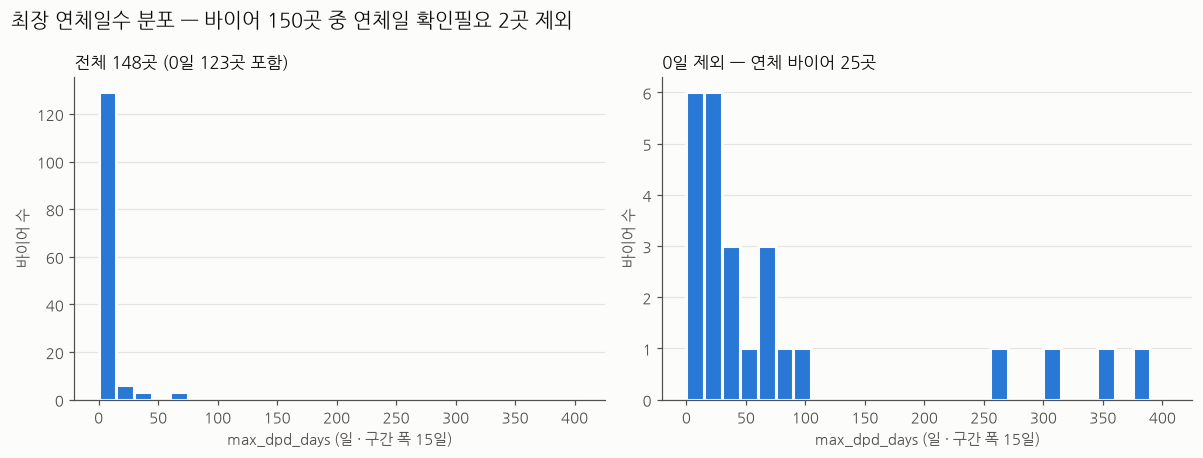

0일 제외 요약: {'count': 25.0, 'mean': 81.0, 'std': 114.0, 'min': 3.0, '25%': 15.0, '50%': 31.0, '75%': 74.0, 'max': 381.0}
aging 구간별 바이어 수: {'1-30': 12, '31-60': 4, '61-90': 5, '91+': 4}
연체일 상위 5: [{'buyer_id': 'B147', 'country_code': 'THA', 'pay_code': 'DA', 'max_dpd_days': 381}, {'buyer_id': 'B044', 'country_code': 'THA', 'pay_code': 'DA', 'max_dpd_days': 355}, {'buyer_id': 'B083', 'country_code': 'USA', 'pay_code': 'OA', 'max_dpd_days': 305}, {'buyer_id': 'B071', 'country_code': 'TWN', 'pay_code': 'OA', 'max_dpd_days': 269}, {'buyer_id': 'B048', 'country_code': 'CHN', 'pay_code': 'OA', 'max_dpd_days': 90}]


In [2]:
# 2. 차트 1 — max_dpd_days 분포 (왼쪽 전체, 오른쪽 0일 제외)
dpd = known["max_dpd_days"].astype(int)
bins = np.arange(0, dpd.max() + 30, 15)  # 구간 폭 15일, [0,15)에는 0일이 들어간다

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
panels = [
    (axes[0], dpd, f"전체 {len(dpd)}곳 (0일 {int((dpd == 0).sum())}곳 포함)"),
    (axes[1], dpd[dpd > 0], f"0일 제외 — 연체 바이어 {int((dpd > 0).sum())}곳"),
]
for ax, data, title in panels:
    ax.hist(data, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xlabel("max_dpd_days (일 · 구간 폭 15일)")
    ax.set_ylabel("바이어 수")
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle(f"최장 연체일수 분포 — 바이어 {len(df)}곳 중 연체일 확인필요 {len(unknown)}곳 제외", x=0.01, ha="left", color=INK, fontsize=13)
fig.tight_layout()
fig.savefig(CHART_DIR / "d1_dpd_hist.png", bbox_inches="tight")
plt.show()

pos = dpd[dpd > 0]
print("0일 제외 요약:", pos.describe().round(1).to_dict())
buckets = pd.cut(pos, [0, 30, 60, 90, np.inf], labels=["1-30", "31-60", "61-90", "91+"])  # codes 시트 aging 구간
print("aging 구간별 바이어 수:", buckets.value_counts(sort=False).to_dict())
print("연체일 상위 5:", known.nlargest(5, "max_dpd_days")[["buyer_id", "country_code", "pay_code", "max_dpd_days"]].to_dict("records"))

### 차트 1 해석
1. 연체 판정 가능 148곳 중 123곳(83.1%)이 0일이고, 연체 바이어는 25곳(16.9%)이다. 왼쪽 그림은 첫 막대(0~14일, 129곳)에 가려 연체 분포가 거의 보이지 않아서 0일 제외 그림을 함께 본다.
2. 연체 25곳의 중앙값은 31일이다. aging 구간별로 1-30일 12곳 · 31-60일 4곳 · 61-90일 5곳으로, 21곳이 90일 안에 몰려 있다.
3. 91일 이상 4곳(B071 TWN 269일 · B083 USA 305일 · B044 THA 355일 · B147 THA 381일)은 떨어진 꼬리이고 평균(81일)을 중앙값보다 크게 끌어올린다. 이 4곳은 `data/data_dictionary.xlsx` codes 시트 91+ 구간 note의 `DPD ≥ 91 (IFRS 9 90일 초과 = 채무불이행 반증 가능 추정)`에 해당하므로 바이어별로 확인할 대상이다.

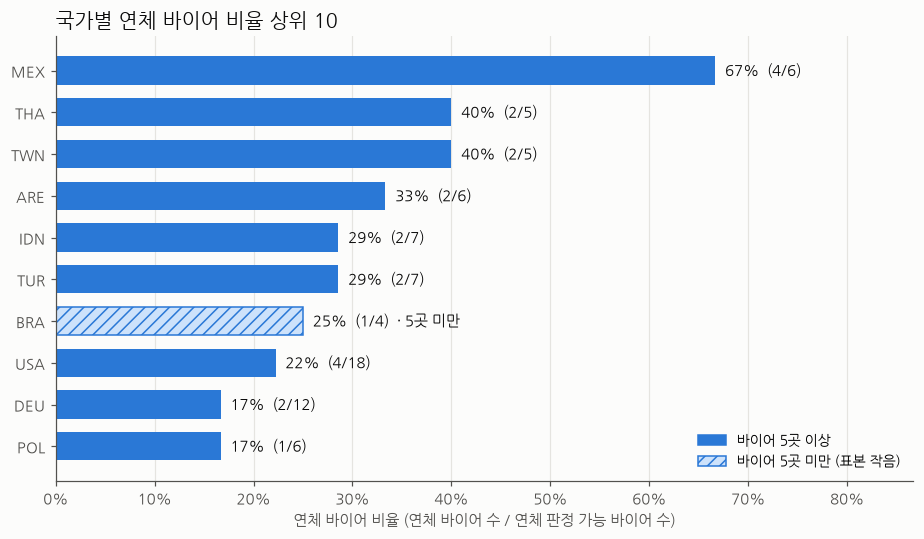

   country_code  n_all  n_known  n_overdue      rate
1           MEX      6        6          4  0.666667
2           THA      5        5          2       0.4
3           TWN      5        5          2       0.4
4           ARE      7        6          2  0.333333
5           IDN      7        7          2  0.285714
6           TUR      7        7          2  0.285714
7           BRA      4        4          1      0.25
8           USA     18       18          4  0.222222
9           DEU     12       12          2  0.166667
10          POL      6        6          1  0.166667
11          IND     10       10          1       0.1
12          VNM     12       12          1  0.083333
13          CHN     14       14          1  0.071429
14          JPN     10       10          0       0.0
15          GBR      6        6          0       0.0
16          NLD      5        5          0       0.0
17          SAU      5        5          0       0.0
18          EGY      4        4          0    

In [3]:
# 3. 차트 2 — 국가별(country_code) 연체 바이어 비율 상위 10
# 정렬: 연체 비율 ↓ → 판정 가능 바이어 수 ↓ → 코드 ↑ (동률이면 표본이 큰 국가 먼저). 바이어 5곳 미만 국가는 옅은 색 + 빗금 + '5곳 미만'
cty = (overdue_rate("country_code").reset_index()
       .sort_values(["rate", "n_known", "country_code"], ascending=[False, False, True]).reset_index(drop=True))
cty.index += 1
top = cty.head(10)
small = top["n_all"] < 5

fig, ax = plt.subplots(figsize=(8.5, 5))
y = np.arange(len(top))[::-1]
bars = ax.barh(y, top["rate"], height=0.68, color=BLUE)
for bar, (_, r), s in zip(bars, top.iterrows(), small):
    if s:
        bar.set_facecolor(BLUE_LIGHT)
        bar.set_edgecolor(BLUE)
        bar.set_hatch("///")
    label = f"{r['rate']:.0%}  ({r['n_overdue']}/{r['n_known']})" + ("  · 5곳 미만" if s else "")
    ax.text(r["rate"] + 0.01, bar.get_y() + bar.get_height() / 2, label, va="center", color=INK, fontsize=9.5)
ax.set_yticks(y, top["country_code"])
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, top["rate"].max() * 1.3)
ax.set_xlabel("연체 바이어 비율 (연체 바이어 수 / 연체 판정 가능 바이어 수)")
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=BLUE, label="바이어 5곳 이상"),
                   Patch(facecolor=BLUE_LIGHT, edgecolor=BLUE, hatch="///", label="바이어 5곳 미만 (표본 작음)")],
          loc="lower right", frameon=False, fontsize=9)
ax.set_title("국가별 연체 바이어 비율 상위 10", loc="left", color=INK, fontsize=13)
fig.tight_layout()
fig.savefig(CHART_DIR / "d1_overdue_by_country.png", bbox_inches="tight")
plt.show()

print(cty.to_string())  # 전체 순위 — 10위 경계의 동률 확인용

### 차트 2 해석
1. MEX가 67%(4/6)로 가장 높고, 2위 THA · TWN(각 40%, 2/5)과도 차이가 크다. 다만 국가별 바이어가 3~18곳뿐이라 1곳만 달라져도 비율이 6~33%p 움직인다. 순위보다 연체 바이어 수(분자)를 함께 읽는다.
2. 상위 10 가운데 바이어 5곳 미만 국가는 BRA(25%, 1/4) 하나이고, 연체 1곳으로 25%가 된 값이라 비교하기 어렵다. 연체 0곳인 국가도 7개국이다(JPN · GBR · NLD · SAU · EGY · MYS · NGA).
3. ARE(33%, 2/6)는 연체일 확인필요인 B066을 분모에서 뺀 값이다. B066은 연체금액이 있으므로 연체로 확인되면 3/7 = 43%가 되어 2위로 올라간다. THA 연체 2곳은 모두 91일 이상(B044 · B147, DA)이다.

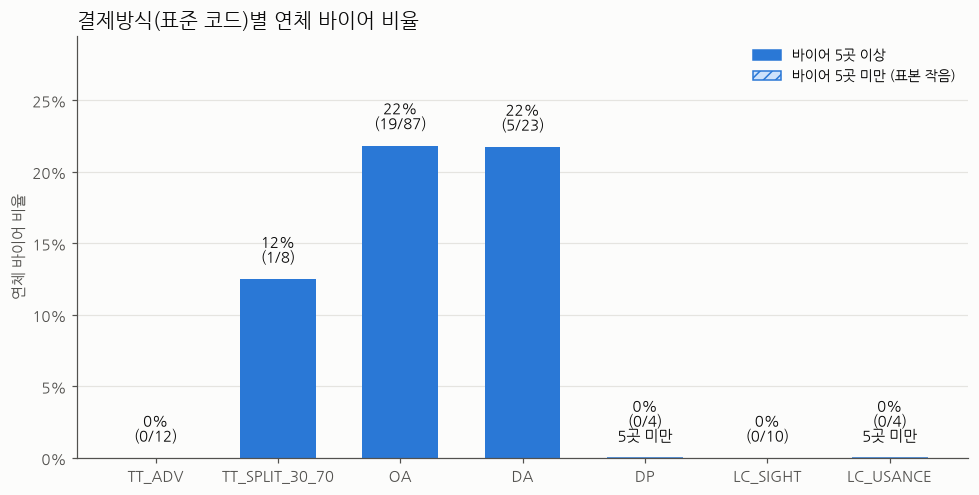

                n_all  n_known  n_overdue      rate
pay_code                                           
TT_ADV             12       12          0       0.0
TT_SPLIT_30_70      8        8          1     0.125
OA                 88       87         19  0.218391
DA                 24       23          5  0.217391
DP                  4        4          0       0.0
LC_SIGHT           10       10          0       0.0
LC_USANCE           4        4          0       0.0

확신 '낮음' 표기를 쓴 바이어: [{'buyer_id': 'B010', 'payment_terms_raw': 'TT', 'pay_code': 'TT_ADV', 'is_overdue': False}, {'buyer_id': 'B036', 'payment_terms_raw': 'TT', 'pay_code': 'TT_ADV', 'is_overdue': False}, {'buyer_id': 'B038', 'payment_terms_raw': 'tt', 'pay_code': 'TT_ADV', 'is_overdue': False}, {'buyer_id': 'B057', 'payment_terms_raw': 'L/C 90 days', 'pay_code': 'LC_USANCE', 'is_overdue': False}, {'buyer_id': 'B060', 'payment_terms_raw': 'tt', 'pay_code': 'TT_ADV', 'is_overdue': False}, {'buyer_id': 'B081', 'payment_terms_raw

In [4]:
# 4. 차트 3 — 결제방식(표준 코드)별 연체 바이어 비율
# 막대 순서 = 데이터 사전 codes 시트(payment_method)에 적힌 순서. 바이어 5곳 미만 코드는 차트 2와 같은 방식으로 표시
ORDER = ["TT_ADV", "TT_SPLIT_30_70", "OA", "DA", "DP", "LC_SIGHT", "LC_USANCE"]
pay = overdue_rate("pay_code").reindex(ORDER)
small_p = pay["n_all"] < 5

fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(len(pay))
bars = ax.bar(x, pay["rate"], width=0.62, color=BLUE)
for bar, (code_, r), s in zip(bars, pay.iterrows(), small_p):
    if s:
        bar.set_facecolor(BLUE_LIGHT)
        bar.set_edgecolor(BLUE)
        bar.set_hatch("///")
    label = f"{r['rate']:.0%}\n({r['n_overdue']}/{r['n_known']})" + ("\n5곳 미만" if s else "")
    ax.text(bar.get_x() + bar.get_width() / 2, r["rate"] + 0.01, label, ha="center", va="bottom", color=INK, fontsize=9.5)
ax.set_xticks(x, pay.index)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, max(pay["rate"].max() * 1.35, 0.1))
ax.set_ylabel("연체 바이어 비율")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=BLUE, label="바이어 5곳 이상"),
                   Patch(facecolor=BLUE_LIGHT, edgecolor=BLUE, hatch="///", label="바이어 5곳 미만 (표본 작음)")],
          loc="upper right", frameon=False, fontsize=9)
ax.set_title("결제방식(표준 코드)별 연체 바이어 비율", loc="left", color=INK, fontsize=13)
fig.tight_layout()
fig.savefig(CHART_DIR / "d1_overdue_by_payterm.png", bbox_inches="tight")
plt.show()

print(pay.to_string())
print("\n확신 '낮음' 표기를 쓴 바이어:", df.loc[df["pay_code_conf"] == "낮음", ["buyer_id", "payment_terms_raw", "pay_code", "is_overdue"]].to_dict("records"))

### 차트 3 해석
1. 연체 바이어 25곳 중 24곳이 OA(22%, 19/87)와 DA(22%, 5/23)에 몰려 있다. 데이터 사전 codes 시트 note를 보면 두 방식은 위험 부담이 수출자에게 있다(OA `위험: 수출자 전부` · DA `위험: 수출자(추심은행 지급보증 없음, URC 522)`).
2. TT_ADV(0/12)와 LC_SIGHT(0/10)는 연체가 0곳이고 TT_SPLIT_30_70은 12%(1/8)다. DP와 LC_USANCE도 0%이지만 각 4곳뿐(5곳 미만)이라 '연체가 없는 방식'이라는 근거로 쓰기는 어렵다.
3. 이 표는 결제방식과 연체가 함께 나타난다는 뜻일 뿐, 결제방식이 연체의 원인이라는 근거는 아니다(국가 · 업종과의 교차는 아직 보지 않았다). 민감도도 작다. 코드표 확신 '낮음' 중 연체는 B085(`10% T/T advance + 90% O/A 90 days` → OA) 1곳이라 코드가 바뀌어도 OA는 21%(18/86)가 된다. DA는 확인필요 B066이 연체로 확인되면 25%(6/24)가 된다.

In [5]:
# 5. outputs/d1_eda_notes.md 쓰기 — 결제방식별 표 + 차트별 해석
# 해석은 저장된 이 노트북의 '### 차트 N 해석' 마크다운 셀을 그대로 옮긴다(해석을 고쳤으면 저장한 뒤 실행).
import nbformat

NB = "workbench/day1/notebooks/d1_eda.ipynb"
NOTES = Path("workbench/day1/outputs/d1_eda_notes.md")
interp = {c.source.splitlines()[0].removeprefix("### ").removesuffix(" 해석"): "\n".join(c.source.splitlines()[1:])
          for c in nbformat.read(NB, as_version=4).cells if c.cell_type == "markdown" and c.source.startswith("### 차트")}

rows = [f"| {code_} | {r.n_all} | {r.n_known} | {r.n_overdue} | {r.rate:.1%} | {r.n_all - r.n_known} |" for code_, r in pay.iterrows()]
tot = pay[["n_all", "n_known", "n_overdue"]].sum()
rows.append(f"| **합계** | {tot.n_all} | {tot.n_known} | {tot.n_overdue} | {tot.n_overdue / tot.n_known:.1%} | {tot.n_all - tot.n_known} |")

charts = [("차트 1", "max_dpd_days 분포 (전체 · 0일 제외)", "d1_dpd_hist.png"),
          ("차트 2", "국가별 연체 바이어 비율 상위 10", "d1_overdue_by_country.png"),
          ("차트 3", "결제방식(표준 코드)별 연체 바이어 비율", "d1_overdue_by_payterm.png")]

text = f"""# 1일차 EDA 노트 — 바이어 연체 현황

- 원본: `data/day1/d1_buyers_raw.xlsx` (`buyers` 시트, 153행) + 코드표 `workbench/day1/outputs/d1_code_table.csv` — 원본은 읽기만 했다.
- 코드: 정리 규칙 `scripts/d1_clean_buyers.py` · 차트와 표 `workbench/day1/notebooks/d1_eda.ipynb`
- **연체 바이어 = `max_dpd_days > 0`**. 연체 바이어 비율 = 연체 바이어 수 ÷ 연체 판정 가능 바이어 수.

## 정리 규칙 (분석용 표는 메모리에서만 만든다)

| 규칙 | 내용 | 결과 |
|---|---|---|
| R1 중복 제거 | buyer_id 기준 첫 행만 남김 (근거: `d1_quality_report.md` 2절) | 153행 → {len(df)}행 |
| R2 결제방식 | `payment_terms_raw`를 코드표 '원래 표기'와 글자 그대로 맞춰 표준 코드 부여 | 미일치 0 · 7종 |
| R3 연체일 | `90일` · `381 days` → 숫자. `-` · `확인중`은 0으로 채우지 않고 '확인필요' | 확인필요 {len(unknown)}곳: {", ".join(f"{r.buyer_id}(`{r.max_dpd_days_raw}`)" for r in unknown.itertuples())} |
| R4 연체 여부 | `max_dpd_days > 0`, 확인필요는 판정 안 함(분모 제외) | 연체 {int(known['is_overdue'].sum())}곳 / 판정 가능 {len(known)}곳 = {known['is_overdue'].mean():.1%} |

## 결제방식별 연체 바이어

| 결제방식(표준 코드) | 바이어 수 | 연체 판정 가능 | 연체 바이어 수 | 연체 바이어 비율 | 연체일 확인필요 |
|---|---|---|---|---|---|
{chr(10).join(rows)}

> 계산식: 연체 바이어 비율 = 연체 바이어 수 ÷ 연체 판정 가능 바이어 수. 연체 판정 가능 = 바이어 수 − 연체일 확인필요.
> 순서는 데이터 사전 codes 시트(payment_method)의 순서. DP · LC_USANCE는 바이어 5곳 미만이라 비율 비교에 주의.
"""
for key, title, png in charts:
    text += f"\n## {key}. {title}\n\n![{title}](charts/{png})\n\n{interp[key]}\n"

NOTES.write_text(text, encoding="utf-8")
print(f"저장: {NOTES} ({len(text.splitlines())}줄)\n")
print(text)

저장: workbench/day1/outputs/d1_eda_notes.md (54줄)

# 1일차 EDA 노트 — 바이어 연체 현황

- 원본: `data/day1/d1_buyers_raw.xlsx` (`buyers` 시트, 153행) + 코드표 `workbench/day1/outputs/d1_code_table.csv` — 원본은 읽기만 했다.
- 코드: 정리 규칙 `scripts/d1_clean_buyers.py` · 차트와 표 `workbench/day1/notebooks/d1_eda.ipynb`
- **연체 바이어 = `max_dpd_days > 0`**. 연체 바이어 비율 = 연체 바이어 수 ÷ 연체 판정 가능 바이어 수.

## 정리 규칙 (분석용 표는 메모리에서만 만든다)

| 규칙 | 내용 | 결과 |
|---|---|---|
| R1 중복 제거 | buyer_id 기준 첫 행만 남김 (근거: `d1_quality_report.md` 2절) | 153행 → 150행 |
| R2 결제방식 | `payment_terms_raw`를 코드표 '원래 표기'와 글자 그대로 맞춰 표준 코드 부여 | 미일치 0 · 7종 |
| R3 연체일 | `90일` · `381 days` → 숫자. `-` · `확인중`은 0으로 채우지 않고 '확인필요' | 확인필요 2곳: B058(`-`), B066(`확인중`) |
| R4 연체 여부 | `max_dpd_days > 0`, 확인필요는 판정 안 함(분모 제외) | 연체 25곳 / 판정 가능 148곳 = 16.9% |

## 결제방식별 연체 바이어

| 결제방식(표준 코드) | 바이어 수 | 연체 판정 가능 | 연체 바이어 수 | 연체 바이어 비율 | 연체일 확인필요 |
|---|---|---|---|---|---|
| TT_ADV | 12 | 12 | 0 | 0.0% | 0 |
| TT_SPLIT_30_70 | 8 | 8 | 1 | 12.5% | 0 |
| OA | 88 | 87 | 19 | 21.8% | 1 |
| DA